# Calibration & Operating-Point Analysis

Rigor pass 2. `class_weight='balanced'` improves recall at the default 0.5 threshold by pushing predicted probabilities up, which harms calibration. This notebook asks two questions on a held-out test split: (1) which model gives **trustworthy probabilities**, and (2) how should the **decision threshold** be chosen from the cost of errors instead of the default 0.5?

Logic in `src/calibration.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import numpy as np, matplotlib.pyplot as plt
from src import calibration as cal

## Probability quality

Four probability sources from the same regularized tree (depth 5, leaf 20): the balanced model, the unweighted model, and the unweighted model calibrated with isotonic and sigmoid. Brier is the calibration score (lower is better); ROC AUC is discrimination.

In [2]:
yte, probs = cal.fit_probabilities()
cal.brier_table(yte, probs)

,model,brier,roc_auc
0,balanced_uncal,0.0314,0.9923
1,unweighted_uncal,0.0118,0.9972
2,unweighted_isotonic,0.0130,0.9968
3,unweighted_sigmoid,0.0130,0.9968


The balanced model is the **worst** calibrated and even slightly worse on ROC AUC. The unweighted tree is already well calibrated out of the box, and post-hoc calibration does not improve it. The miscalibration was self-inflicted by the class weights, not a property of the tree.

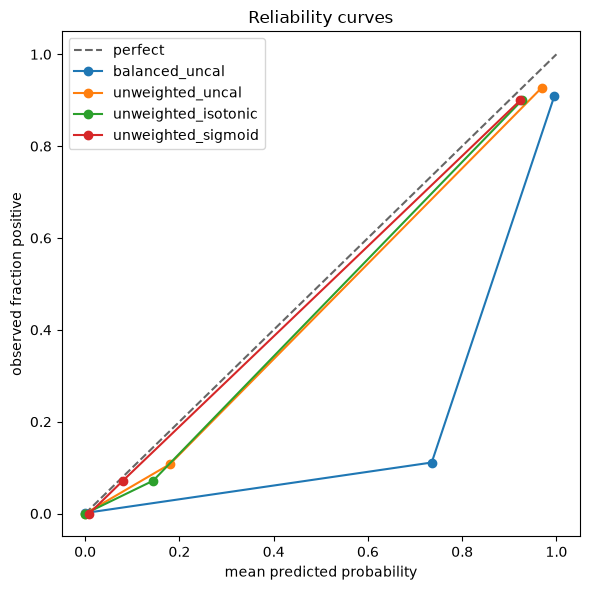

In [3]:
rel = cal.reliability(yte, probs, n_bins=10)
plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1],'k--',alpha=.6,label='perfect')
for name,(mean,frac) in rel.items():
    plt.plot(mean, frac, marker='o', label=name)
plt.xlabel('mean predicted probability'); plt.ylabel('observed fraction positive')
plt.title('Reliability curves'); plt.legend(); plt.tight_layout()
plt.savefig(_root/'results'/'reliability_curve.png', dpi=120); plt.show()

## Choosing the operating point

On the well-calibrated unweighted model, sweep the threshold and read off the precision/recall trade. The default 0.5 is just one point on this curve.

In [4]:
sweep = cal.threshold_sweep(yte, probs['unweighted_isotonic'])
sweep

,threshold,precision,recall,f1,flagged
0,0.05,0.625,0.990,0.766,152
1,0.10,0.683,0.990,0.809,139
2,0.15,0.688,0.990,0.812,138
3,0.20,0.752,0.948,0.839,121
4,0.25,0.784,0.948,0.858,116
5,0.30,0.820,0.948,0.879,111
6,0.35,0.827,0.948,0.883,110
7,0.40,0.843,0.948,0.892,108
8,0.45,0.892,0.948,0.919,102
9,0.50,0.900,0.938,0.918,100


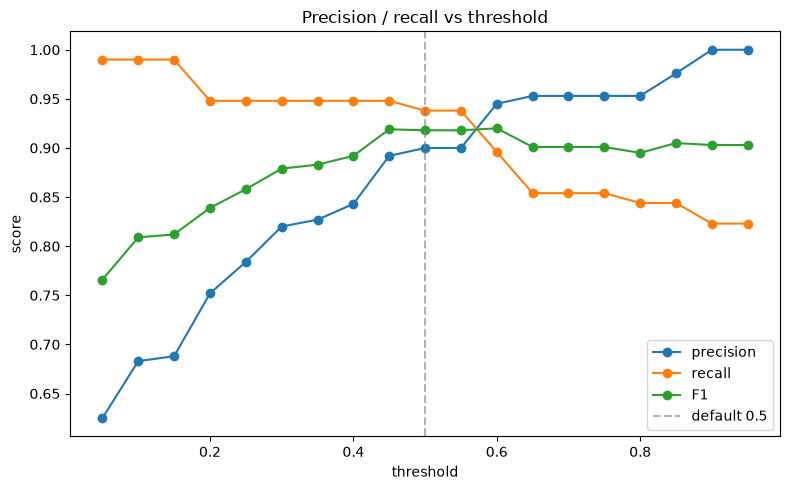

In [5]:
plt.figure(figsize=(8,5))
plt.plot(sweep['threshold'], sweep['precision'], marker='o', label='precision')
plt.plot(sweep['threshold'], sweep['recall'], marker='o', label='recall')
plt.plot(sweep['threshold'], sweep['f1'], marker='o', label='F1')
plt.axvline(0.5, color='gray', ls='--', alpha=.6, label='default 0.5')
plt.xlabel('threshold'); plt.ylabel('score'); plt.title('Precision / recall vs threshold')
plt.legend(); plt.tight_layout()
plt.savefig(_root/'results'/'threshold_tradeoff.png', dpi=120); plt.show()

In [6]:
from sklearn.metrics import recall_score, precision_score
p=probs['balanced_uncal']; pred=(p>=0.5).astype(int)
print(f"balanced @0.5 (reference): recall={recall_score(yte,pred):.3f} precision={precision_score(yte,pred):.3f}")
print('target recall>=0.90 :', cal.threshold_for_recall(yte, probs['unweighted_isotonic'], 0.90))
print('cost FN:FP = 5:1   :', cal.threshold_by_cost(yte, probs['unweighted_isotonic'], 5, 1))
print('cost FN:FP = 10:1  :', cal.threshold_by_cost(yte, probs['unweighted_isotonic'], 10, 1))

balanced @0.5 (reference): recall=0.990 precision=0.660
target recall>=0.90 : {'threshold': 0.553, 'precision': 0.9, 'recall': 0.938}
cost FN:FP = 5:1   : {'threshold': 0.48, 'cost': 35.0, 'fn': 5, 'fp': 10, 'recall': 0.948, 'precision': 0.901}
cost FN:FP = 10:1  : {'threshold': 0.11, 'cost': 53.0, 'fn': 1, 'fp': 43, 'recall': 0.99, 'precision': 0.688}


The threshold dominates the fixed balanced-weight point: a calibrated model reaches the same recall (0.99) at equal-or-better precision, or trades to recall 0.95 / precision 0.90 when false positives matter more. The cost ratio makes the choice explicit. See `docs/learnings.md` for the full read.